In [6]:
# ייבוא ספריות טעינת הדאטה וקביעת מצב אקראי קבוע
import pandas as pd
import numpy as np

RANDOM_STATE = 42  # Required by the assignment
df = pd.read_csv("dataset.csv")
print(df.shape)

(45000, 30)


## עמודה A: customer_id_hash
מזהה לקוח מוצפן. לכל נהג יש קוד ייחודי, ולכן אין בעמודה מידע שיכול לעזור בחיזוי, ונהג חדש יגיע תמיד עם קוד שהמודל לא ראה. העמודה תוסר.

In [13]:
# בדיקה שכל מזהה לקוח מופיע פעם אחת בלבד
print("Unique IDs:", df["customer_id_hash"].is_unique)

Unique IDs: True


## עמודה B: agent_code
קוד הסוכן שמכר את הפוליסה. הסוכן ידוע ביום החתימה ולכן אין כאן דליפת מידע.
נבדוק את אחידות הפורמט, את מספר הסוכנים, את כמות הנהגים לכל סוכן ואת הקשר לעלות התביעות.

In [7]:
# בדיקת ערכים חסרים ובדיקה שכל הקודים באותו פורמט של אות ושלוש ספרות
print("Missing:", df["agent_code"].isna().sum())
print("Valid format:", df["agent_code"].str.match(r"^A\d{3}$").mean())

Missing: 0
Valid format: 1.0


In [8]:
# כמה סוכנים יש וכמה נהגים יש לכל סוכן
counts = df["agent_code"].value_counts()
print("Number of agents:", counts.size)
counts.describe()

Number of agents: 300


count     300.000000
mean      150.000000
std       235.319423
min        35.000000
25%        64.000000
50%        87.000000
75%       140.250000
max      2791.000000
Name: count, dtype: float64

In [9]:
# עלות ממוצעת לפי סוכן אצל הסוכנים הקטנים לעומת הגדולים
agent_stats = df.groupby("agent_code")["annual_claim_cost"].agg(["mean", "count"])
print("Small agents under 100 drivers")
print(agent_stats[agent_stats["count"] < 100]["mean"].describe().round(0))
print("\nLarge agents with 200 drivers or more")
print(agent_stats[agent_stats["count"] >= 200]["mean"].describe().round(0))

Small agents under 100 drivers
count     179.0
mean     3016.0
std       955.0
min       726.0
25%      2370.0
50%      2864.0
75%      3605.0
max      6641.0
Name: mean, dtype: float64

Large agents with 200 drivers or more
count      45.0
mean     3013.0
std       426.0
min      2135.0
25%      2764.0
50%      3048.0
75%      3218.0
max      4070.0
Name: mean, dtype: float64


In [10]:
# בדיקה האם כל סוכן עובד במדינה אחת או בכמה מדינות
df.groupby("agent_code")["country"].nunique().describe()

count    300.000000
mean       9.896667
std        0.315681
min        8.000000
25%       10.000000
50%       10.000000
75%       10.000000
max       10.000000
Name: country, dtype: float64

In [12]:
# בדיקת ערבוב: מערבבים את העלויות בין הנהגים ובודקים אם הפיזור האמיתי בין הסוכנים גדול ממה שמקריות יוצרת
rng = np.random.default_rng(RANDOM_STATE)
y = df["annual_claim_cost"].values
agents = df["agent_code"].values

real_spread = pd.Series(y).groupby(agents).mean().std()
shuffled_spreads = [pd.Series(rng.permutation(y)).groupby(agents).mean().std() for _ in range(300)]

print("Real spread between agents:     ", round(real_spread))
print("Average spread after shuffling: ", round(np.mean(shuffled_spreads)))
print("Share of shuffles with larger spread:", round(np.mean(np.array(shuffled_spreads) >= real_spread), 2))

Real spread between agents:      807
Average spread after shuffling:  803
Share of shuffles with larger spread: 0.44


### מסקנה לגבי agent_code
העמודה נקייה, ללא חסרים ובפורמט אחיד. יש 300 סוכנים, רובם קטנים, וכמעט כל סוכן עובד בכל המדינות.
בבדיקת ערבוב, הפיזור האמיתי בין הסוכנים דומה לפיזור שמתקבל כשמערבבים את העלויות באקראי. כלומר, ההבדלים בין הסוכנים מוסברים במקריות.
לכן העמודה תוסר. הוספתה הייתה מוסיפה למודל 300 עמודות ללא מידע ומגדילה את הסיכון ל-overfitting.

In [ ]:
# רשימת העמודות מהחלק שלי שיוסרו מהמודל
DROP_COLS_DRIVER = ["customer_id_hash", "agent_code"]

## עמודה C: country
מדינת הפוליסה. זו עמודה קטגוריאלית עם 10 מדינות. המדינה ידועה ביום החתימה ולכן אין כאן דליפת מידע.
נבדוק את אחידות הערכים, את כמות הנהגים בכל מדינה ואת הקשר בין המדינה לעלות התביעות.

In [14]:
# בדיקת ערכים חסרים ורשימת המדינות עם מספר הנהגים בכל אחת
print("Missing:", df["country"].isna().sum())
df["country"].value_counts()

Missing: 0


country
US    9907
DE    5789
GB    5394
FR    4536
IT    4508
IL    4455
ES    3739
BR    3156
PL    2181
JP    1335
Name: count, dtype: int64

In [15]:
# השוואת עלות התביעות בין המדינות לפי שלושה מדדים
country_stats = df.groupby("country")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3).sort_values("avg_cost")
country_stats

,avg_cost,share_with_claim,share_expensive,drivers
country,,,,
JP,973.666,0.196,0.022,1335
BR,1197.146,0.412,0.013,3156
PL,1247.617,0.379,0.017,2181
ES,1625.003,0.347,0.031,3739
GB,1976.434,0.266,0.059,5394
IT,2049.465,0.350,0.053,4508
FR,2130.829,0.301,0.058,4536
DE,2819.795,0.297,0.093,5789
IL,2993.003,0.369,0.090,4455


### מסקנה לגבי country
העמודה נקייה, עם 10 מדינות וללא ערכים חסרים. יש הבדל גדול ועקבי בעלות בין המדינות, פי 6.7 בין יפן לארה"ב, ובכל מדינה יש אלפי נהגים ולכן ההבדל אינו מקרי. העמודה תישאר.
יש מדינות עם הרבה תביעות קטנות, כמו ברזיל, ומדינות עם תביעות גדולות, כמו ארה"ב.
בפונקציית הניקוי נוסיף חוק שמאחד כתיבה, כדי להגן מפני וריאנטים בקובץ הבדיקה. את המרת המדינה לעמודות 0 ו-1 נבצע בתוך ה-Pipeline.

## עמודה D: area_type
סוג אזור המגורים: עיר, פרבר או כפר. זו עמודה קטגוריאלית שידועה ביום החתימה.
נבדוק את אחידות הערכים, את הקשר לעלות התביעות ואת הקשר לעמודת צפיפות האוכלוסייה.

In [21]:
# בדיקת ערכים חסרים ורשימת סוגי האזורים עם מספר הנהגים בכל אחד
print("Missing:", df["area_type"].isna().sum())
df["area_type"].value_counts()

Missing: 0


area_type
urban       18329
suburban    18086
rural        8585
Name: count, dtype: int64

In [22]:
# השוואת עלות התביעות בין סוגי האזורים לפי שלושה מדדים
df.groupby("area_type")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
area_type,,,,
rural,3751.261,0.297,0.121,8585
suburban,3062.542,0.344,0.095,18086
urban,2711.231,0.383,0.077,18329


In [23]:
# בדיקה האם סוג האזור מתאים לצפיפות האוכלוסייה שרשומה לנהג
df.groupby("area_type")["region_density"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
area_type,,,,,,,,
rural,8585.0,74.0,59.0,4.0,35.0,58.0,93.0,602.0
suburban,18086.0,991.0,563.0,121.0,611.0,863.0,1227.0,8205.0
urban,18329.0,3619.0,2413.0,299.0,1970.0,2997.0,4541.0,20000.0


### מסקנה לגבי area_type
העמודה נקייה, עם שלושה ערכים וללא חסרים. בעיר יש יותר תביעות אך קטנות יותר, ובכפר פחות תביעות אך יקרות יותר, ולכן העמודה משפיעה על העלות ותישאר.
הצפיפות מתאימה לסוג האזור ברוב המקרים. החפיפה הקטנה בקצוות נובעת כנראה מהגדרות שונות בין מדינות ואינה שגיאה.
בפונקציית הניקוי נוסיף חוק שמאחד כתיבה. את המרת האזור לעמודות 0 ו-1 נבצע בתוך ה-Pipeline.

## עמודה E: region_density
צפיפות האוכלוסייה באזור המגורים, כלומר מספר התושבים לקמ"ר. זו עמודה מספרית שידועה ביום החתימה.
נבדוק ערכים חסרים וערכים לא הגיוניים, את צורת ההתפלגות ואת הקשר לעלות התביעות.

In [25]:
# בדיקת ערכים חסרים וסטטיסטיקה תיאורית של הצפיפות
print("Missing:", df["region_density"].isna().sum())
df["region_density"].describe().round(0)

Missing: 0


count    45000.0
mean      1887.0
std       2161.0
min          4.0
25%        498.0
50%       1151.0
75%       2593.0
max      20000.0
Name: region_density, dtype: float64

In [26]:
# בדיקת הערכים הגבוהים ביותר וכמה נהגים יש בערך המקסימלי
print("Drivers at max value 20000:", (df["region_density"] == 20000).sum())
df["region_density"].sort_values(ascending=False).head(10).values

Drivers at max value 20000: 21


array([20000, 20000, 20000, 20000, 20000, 20000, 20000, 20000, 20000,
       20000], dtype=int64)

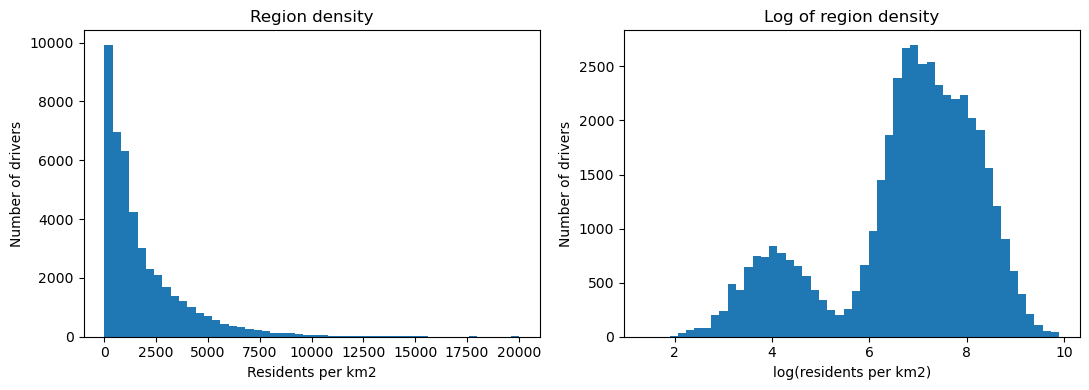

In [27]:
# היסטוגרמה של הצפיפות בסקאלה רגילה ובסקאלה לוגריתמית
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["region_density"], bins=50)
axes[0].set_title("Region density")
axes[0].set_xlabel("Residents per km2")
axes[0].set_ylabel("Number of drivers")

axes[1].hist(np.log(df["region_density"]), bins=50)
axes[1].set_title("Log of region density")
axes[1].set_xlabel("log(residents per km2)")
axes[1].set_ylabel("Number of drivers")
plt.tight_layout()
plt.show()

In [28]:
# חלוקת הנהגים לחמש קבוצות שוות לפי צפיפות והשוואת עלות התביעות בין הקבוצות
density_group = pd.qcut(df["region_density"], 5)
df.groupby(density_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
region_density,,,,
"(3.999, 315.0]",3786.514,0.302,0.122,9003
"(315.0, 863.0]",3348.248,0.355,0.106,9020
"(863.0, 1556.0]",2804.753,0.347,0.086,8979
"(1556.0, 3079.0]",2678.152,0.364,0.075,9000
"(3079.0, 20000.0]",2634.969,0.387,0.074,8998


### מסקנה לגבי region_density
העמודה ללא חסרים וללא ערכים שליליים. 21 נהגים בערך 20,000, כולם באזור עירוני, וזו כנראה תקרת רישום ולא שגיאה.
ההתפלגות מוטה ימינה עם זנב ארוך. בסקאלה לוגריתמית מופיעות שתי קבוצות, כפרים מול ערים ופרברים, בהתאמה ל-area_type.
העלות יורדת ככל שהצפיפות עולה, וההשפעה חזקה בעיקר באזורים דלילים. מועמד לפיצ'ר מהונדס: לוגריתם של הצפיפות.
בפונקציית הניקוי נוסיף חוק שמוודא שהערך מספרי וחיובי, וערך לא תקין יהפוך לחסר.

## עמודה F: winter_severity
חומרת החורף באזור המגורים, בסולם 0 עד 10 לפי מילון השדות, כאשר 0 הוא כמעט ללא חורף. זו עמודה מספרית שידועה ביום החתימה.
נבדוק שכל הערכים בטווח החוקי, שהערכים הגיוניים לפי מדינה, ואת הקשר לעלות התביעות.

In [31]:
# בדיקת ערכים חסרים ובדיקה שכל הערכים בטווח החוקי של אפס עד עשר
print("Missing:", df["winter_severity"].isna().sum())
print("Out of range:", ((df["winter_severity"] < 0) | (df["winter_severity"] > 10)).sum())
df["winter_severity"].describe().round(2)

Missing: 0
Out of range: 0


count    45000.00
mean         3.46
std          2.21
min          0.00
25%          1.70
50%          3.30
75%          5.00
max         10.00
Name: winter_severity, dtype: float64

In [32]:
# בדיקה האם חומרת החורף הגיונית לפי מדינה
df.groupby("country")["winter_severity"].agg(["mean", "min", "max"]).round(1).sort_values("mean")

,mean,min,max
country,,,
BR,0.6,0.0,2.3
IL,1.1,0.0,3.6
ES,2.1,0.0,6.5
GB,3.1,0.0,6.6
IT,3.1,0.0,8.8
FR,3.6,0.0,9.5
JP,4.5,0.0,10.0
US,4.6,0.0,10.0
DE,5.1,0.0,10.0


In [33]:
# חלוקת הנהגים לקבוצות לפי חומרת החורף והשוואת עלות התביעות
winter_group = pd.cut(df["winter_severity"], bins=[-0.01, 1, 3, 5, 7, 10])
df.groupby(winter_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
winter_severity,,,,
"(-0.01, 1.0]",2248.726,0.373,0.060,7311
"(1.0, 3.0]",2727.048,0.341,0.080,13320
"(3.0, 5.0]",2968.202,0.331,0.091,13573
"(5.0, 7.0]",3902.434,0.364,0.126,7789
"(7.0, 10.0]",4602.491,0.397,0.147,3007


In [34]:
# השוואת הקשר בין חומרת החורף לעלות בכל הדאטה לעומת בתוך כל מדינה בנפרד
print("All drivers:", round(df["winter_severity"].corr(df["annual_claim_cost"]), 3))
for c in ["US", "DE", "PL", "IL"]:
    d = df[df["country"] == c]
    print(c, round(d["winter_severity"].corr(d["annual_claim_cost"]), 3))

All drivers: 0.087
US 0.037
DE 0.021
PL 0.062
IL 0.029


### מסקנה לגבי winter_severity
העמודה ללא חסרים, וכל הערכים בטווח החוקי 0 עד 10. הערכים הגיוניים לפי מדינה: ברזיל וישראל מתונות, פולין וגרמניה קרות.
ככל שהחורף קשה יותר העלות הממוצעת ואחוז הנהגים היקרים עולים, אך אחוז הנהגים שתובעים כמעט לא משתנה. כלומר, בחורף קשה התאונות יקרות יותר ולא בהכרח שכיחות יותר.
חלק מהקשר נובע מהמדינה (משתנה מבלבל): בתוך כל מדינה הקשר חלש יותר, אך עדיין חיובי. העמודה תישאר, והמודל יפריד בין השפעת המדינה להשפעת החורף.
בפונקציית הניקוי נוסיף חוק שמוודא שהערך מספרי ובטווח 0 עד 10, וערך מחוץ לטווח יהפוך לחסר.

## עמודה G: driver_age
גיל הנהג בשנים. זו עמודה מספרית שידועה ביום החתימה, ועליה מבוססים סעיפי חקירת הנתונים 2.3 ו-2.4.
נבדוק שהגילאים חוקיים והגיוניים, את התפלגות הגילאים, ואת הקשר בין הגיל לעלות התביעות.

In [36]:
# בדיקת ערכים חסרים סוג הנתונים והגיל הנמוך והגבוה ביותר
print("Missing:", df["driver_age"].isna().sum())
print("Type:", df["driver_age"].dtype)
print("Min age:", df["driver_age"].min(), "| Max age:", df["driver_age"].max())

Missing: 0
Type: int64
Min age: 18 | Max age: 90


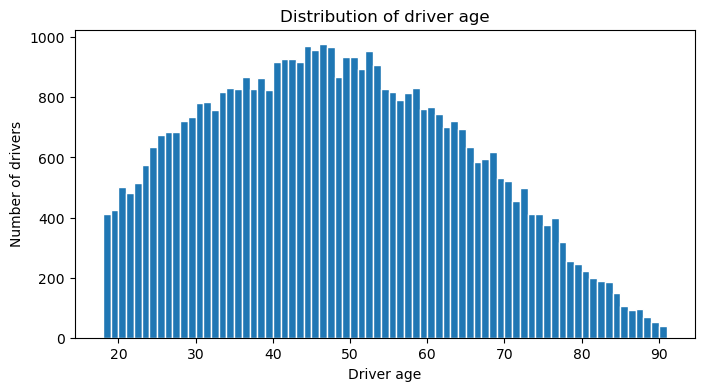

In [37]:
# היסטוגרמה של גילאי הנהגים
plt.figure(figsize=(8, 4))
plt.hist(df["driver_age"], bins=range(18, 92), edgecolor="white")
plt.title("Distribution of driver age")
plt.xlabel("Driver age")
plt.ylabel("Number of drivers")
plt.show()

In [38]:
# חלוקת הנהגים לקבוצות גיל והשוואת עלות התביעות
age_group = pd.cut(df["driver_age"], bins=[17, 24, 34, 44, 54, 64, 74, 90])
df.groupby(age_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
driver_age,,,,
"(17, 24]",5838.546,0.590,0.169,3542
"(24, 34]",3393.102,0.385,0.101,7473
"(34, 44]",2916.300,0.346,0.091,8871
"(44, 54]",2789.977,0.331,0.087,9219
"(54, 64]",2722.653,0.334,0.080,7642
"(64, 74]",1901.850,0.238,0.058,5262
"(74, 90]",2957.455,0.303,0.093,2991


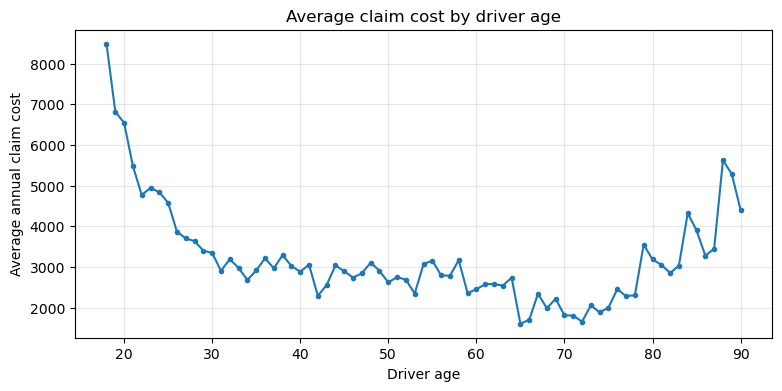

In [39]:
# גרף של העלות הממוצעת לכל גיל בנפרד
avg_by_age = df.groupby("driver_age")["annual_claim_cost"].mean()
plt.figure(figsize=(9, 4))
plt.plot(avg_by_age.index, avg_by_age.values, marker="o", markersize=3)
plt.title("Average claim cost by driver age")
plt.xlabel("Driver age")
plt.ylabel("Average annual claim cost")
plt.grid(alpha=0.3)
plt.show()

### מסקנה לגבי driver_age
העמודה ללא חסרים, וכל הגילאים חוקיים, בין 18 ל-90. רוב הנהגים בגילאי 40 עד 50, ומעל 85 יש מעט נהגים, ולכן הממוצעים שם רועשים.
הקשר בין הגיל לעלות הוא בצורת U: צעירים בני 18 עד 24 יקרים פי שניים מגילאי הביניים, העלות הנמוכה ביותר בגילאי 65 עד 74, ומעל 75 היא עולה שוב.
מודל לינארי עם גיל בלבד לא יוכל ללמוד צורה כזו. לכן מועמדים לפיצ'רים מהונדסים: גיל בריבוע, דגל נהג צעיר, וקבוצות גיל.
בפונקציית הניקוי נוסיף חוק שמוודא שהגיל מספרי ובטווח סביר של 16 עד 100, וערך מחוץ לטווח יהפוך לחסר.

## עמודה H: gender
מין הנהג. לפי מילון השדות הערכים האפשריים הם M לגבר ו-F לאישה. זו עמודה קטגוריאלית שידועה ביום החתימה.
נבדוק את אחידות הכתיבה, נאחד את הערכים לשני ערכים תקניים, ונבדוק את הקשר לעלות התביעות.

In [41]:
# כל הערכים השונים שמופיעים בעמודה כולל ערכים חסרים
df["gender"].value_counts(dropna=False)

gender
M         23624
F         20224
Male        232
m           195
female      187
male        187
f           177
Female      174
Name: count, dtype: int64

In [42]:
# הצגת כל ערך עם גרשיים כדי לחשוף רווחים מוסתרים לפני או אחרי הטקסט
df["gender"].map(repr).value_counts()

gender
'M'         23624
'F'         20224
'Male'        232
'm'           195
'female'      187
'male'        187
'f'           177
'Female'      174
Name: count, dtype: int64

In [43]:
# איחוד הכתיבה לשני ערכים תקניים לפי מילון מיפוי ובדיקה שלא נשארו ערכים לא מוכרים
gender_map = {"m": "M", "male": "M", "f": "F", "female": "F"}
gender_clean = df["gender"].str.strip().str.lower().map(gender_map)
print("Unmapped values:", gender_clean.isna().sum())
gender_clean.value_counts()

Unmapped values: 0


gender
M    24238
F    20762
Name: count, dtype: int64

In [44]:
# השוואת עלות התביעות בין גברים לנשים אחרי האיחוד
df.groupby(gender_clean)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
gender,,,,
F,2745.651,0.336,0.082,20762
M,3312.264,0.363,0.101,24238


### מסקנה לגבי gender
בעמודה 8 צורות כתיבה שונות לשני ערכים, ו-1,152 שורות כתובות בצורה לא תקנית, מפוזרות באופן אחיד בין המדינות. אין ערכים חסרים.
האיחוד נעשה לפי מילון מיפוי מפורש ולא לפי האות הראשונה, כדי שערך לא מוכר יהפוך לחסר ולא יסווג בטעות.
גברים עולים בממוצע כ-21% יותר מנשים, גם בגלל מעט יותר תביעות וגם בגלל יותר תביעות יקרות. העמודה תישאר, וההוגנות של השימוש בה תידון בסעיף 7.

In [45]:
# פונקציית הניקוי של עמודות הנהג שנוסיף לה חוק אחרי כל עמודה שנבדוק
def clean_driver_cols(df):
    df = df.copy()

    # מדינה: הסרת רווחים והמרה לאותיות גדולות
    df["country"] = df["country"].str.strip().str.upper()

    # סוג אזור: הסרת רווחים והמרה לאותיות קטנות
    df["area_type"] = df["area_type"].str.strip().str.lower()

    # צפיפות: המרה למספר, וערך שאינו מספר או שאינו חיובי הופך לחסר
    df["region_density"] = pd.to_numeric(df["region_density"], errors="coerce")
    df.loc[df["region_density"] <= 0, "region_density"] = np.nan

    # חומרת חורף: המרה למספר, וערך מחוץ לטווח אפס עד עשר הופך לחסר
    df["winter_severity"] = pd.to_numeric(df["winter_severity"], errors="coerce")
    df.loc[(df["winter_severity"] < 0) | (df["winter_severity"] > 10), "winter_severity"] = np.nan

    # גיל: המרה למספר, וגיל מתחת לשש עשרה או מעל מאה הופך לחסר
    df["driver_age"] = pd.to_numeric(df["driver_age"], errors="coerce")
    df.loc[(df["driver_age"] < 16) | (df["driver_age"] > 100), "driver_age"] = np.nan

    # מגדר: הסרת רווחים ואותיות קטנות ומיפוי לשני ערכים תקניים, וערך לא מוכר הופך לחסר
    gender_map = {"m": "M", "male": "M", "f": "F", "female": "F"}
    df["gender"] = df["gender"].astype(str).str.strip().str.lower().map(gender_map)

    return df

# בדיקה שהפונקציה רצה על כל הדאטה ועל שורה בודדת
print(clean_driver_cols(df).shape)
print(clean_driver_cols(df.iloc[[0]]).shape)

# בדיקה שאחרי הניקוי נשארו רק שני ערכים תקניים במגדר
clean_driver_cols(df)["gender"].value_counts(dropna=False)

(45000, 30)
(1, 30)


gender
M    24238
F    20762
Name: count, dtype: int64